![Banner](../images/09_03_banner_rs_rader.png)


# Compact-polarimetry (CP)

This notebook explains compact polarimetry, the RCM mode that transmits a circularly polarised wave and receives two linear polarisations, and simulates it from a real RADARSAT-2 quad-pol scene to compute compact-pol decompositions.


## Overview

Compact-polarimetry (CP) is a SAR mode where the radar transmits a circularly polarized wave (commonly RH or LH) and receives two orthogonal linear polarizations (Horizontal, RH and Vertical, RV). This enables the construction of a 2×2 complex covariance matrix, capturing much of the information of full quad-pol but at the cost and coverage of dual-pol.

- The radar records complex scattering coefficients: **S<sub>RH</sub>** and **S<sub>RV</sub>** (where RH = Received Horizontal, RV = Received Vertical, both after transmitting Right-Circular polarization).

- The covariance matrix **[C<sub>2</sub>]** is formed as:

  ```
  C₂ = | <|S_RH|²>      <S_RH S_RV*>   |
       | <S_RV S_RH*>   <|S_RV|²>      |
  ```
  or, in markdown math:
  $$
  \mathbf{C}_2 =
  \begin{bmatrix}
    \langle |S_{\mathrm{RH}}|^2 \rangle & \langle S_{\mathrm{RH}} S_{\mathrm{RV}}^* \rangle \\
    \langle S_{\mathrm{RV}} S_{\mathrm{RH}}^* \rangle & \langle |S_{\mathrm{RV}}|^2 \rangle
  \end{bmatrix}
  $$
  where ⟨·⟩ indicates spatial averaging (speckle filtering).

- From this, you compute **Stokes parameters**:

  - $S_0 = \langle |S_{\mathrm{RH}}|^2 \rangle + \langle |S_{\mathrm{RV}}|^2 \rangle$ (total intensity)
  - $S_1 = \langle |S_{\mathrm{RH}}|^2 \rangle - \langle |S_{\mathrm{RV}}|^2 \rangle$
  - $S_2 = 2 \, \operatorname{Re}(\langle S_{\mathrm{RH}} S_{\mathrm{RV}}^* \rangle)$ (real part)
  - $S_3 = \pm 2 \, \operatorname{Im}(\langle S_{\mathrm{RH}} S_{\mathrm{RV}}^* \rangle)$ (imaginary part; sign depends on handedness convention)

- The **degree of polarization** is:

  $$
  m = \frac{\sqrt{S_1^2 + S_2^2 + S_3^2}}{S_0}
  $$
  This describes how "purely" the scene scatters polarization (low *m* = depolarized, e.g., vegetation).

- The **ellipticity angle** ($\chi$) (indicates even vs. odd bounce) is:

  $$
  \sin 2\chi = -\frac{S_3}{m S_0}
  $$
  Negative means odd-bounce dominant (e.g., double-bounce in urban or flooded areas).

- The **relative phase** ($\delta$) between RH and RV is:

  $$
  \delta = \arctan\left(\frac{S_3}{S_2}\right)
  $$

**m-χ decomposition:** This produces an RGB visualization to distinguish scattering types:
- **Red channel (Double-bounce):** $ \sqrt{m S_0 \frac{1-\sin 2\chi}{2}} $
- **Green channel (Volume):** $ \sqrt{S_0 (1-m)} $
- **Blue channel (Surface):** $ \sqrt{m S_0 \frac{1+\sin 2\chi}{2}} $

Thus, compact-pol SAR enables physically interpretable, information-rich products using rigorous polarimetric math.


## Core concepts

### Learning objectives

1. Describe compact polarimetry as a circular transmit and two linear receives, and the 2x2 covariance matrix that follows.
2. Compute the Stokes parameters, degree of polarization, ellipticity angle, and RH-RV relative phase.
3. Form the m-chi decomposition and read the red, green, and blue channels as double-bounce, volume, and surface.
4. Simulate a right-circular compact-pol acquisition from the measured RADARSAT-2 quad-pol scattering matrix.
5. Check the surface and double-bounce assignment on canonical odd-bounce and even-bounce scatterers.
6. Compare the simulated power fractions with the quad-pol H-alpha zones of the Mecklenburg Lake District scene.
7. Display an m-chi RGB composite in radar geometry and set it beside the quad-pol Pauli RGB.

### Contents

1. Compact-polarimetry (CP) processing
2. Real data: simulating RCM's compact-pol from a real RADARSAT-2 quad-pol scene
3. Takeaways and limitations


## Compact-polarimetry (CP) processing

CP is what distinguishes RCM. It captures much of quad-pol's information at dual-pol cost and swath width.

**1. Covariance matrix.** From the calibrated complex RH and RV channels, form the 2×2 covariance matrix [C2]:
- ⟨|RH|²⟩, ⟨|RV|²⟩, ⟨RH·RV*⟩
- ⟨ ⟩ denotes spatial averaging, which is the polarimetric speckle filter.

**2. Stokes parameters**
- S₀ = ⟨|RH|²⟩ + ⟨|RV|²⟩ is the total power.
- S₁ = ⟨|RH|²⟩ − ⟨|RV|²⟩
- S₂ = 2 Re⟨RH·RV*⟩
- S₃ = ±2 Im⟨RH·RV*⟩. The sign depends on transmit handedness, so check the convention in your software.

**3. Derived parameters**
- **Degree of polarization:** m = √(S₁² + S₂² + S₃²) / S₀
  - Low m means depolarized, volume-like scattering, as in vegetation.
- **Ellipticity angle:** sin 2χ = −S₃ / (m·S₀)
  - Indicates odd versus even bounce.
- **Relative phase:** δ = arctan(S₃ / S₂)

**4. m-χ decomposition (Raney).** This gives an RGB composite:
- Double bounce = √[m·S₀·(1 − sin 2χ)/2], displayed in red. Indicates buildings and flooded vegetation.
- Volume = √[S₀·(1 − m)], displayed in green. Indicates forest and crop canopy.
- Surface = √[m·S₀·(1 + sin 2χ)/2], displayed in blue. Indicates bare soil and water.
- **m-δ decomposition** follows the same logic, using δ in place of χ.

**5. Other CP products**
- Circular polarization ratio (CPR) indicates surface roughness and is used for sea ice.
- RH/RV backscatter and the conformity coefficient are used for soil moisture.
- **Pseudo-quad reconstruction** (Souyris or Nord methods) estimates a full 3×3 matrix. This lets you apply quad-pol decompositions such as Freeman-Durden or H/A/α.

**6. Order of operations.** Terrain-correct the decomposition outputs *after* computing them, not before. Resampling complex data first corrupts the phase relationships.

**Applications:** crop type and phenology, wetland classes (open water vs. flooded vegetation vs. marsh), sea-ice typing, and oil-slick vs. look-alike discrimination.


## Real data: simulating RCM's compact-pol from a real RADARSAT-2 quad-pol scene

RADARSAT-2 carries no compact-pol hardware -- only RCM does. There is consequently no real RS2
compact-pol product to read. What the compact-pol literature does instead (and what this
notebook does) is **simulate** a compact-pol acquisition from a real quad-pol scene: apply the
transmitted-wave physics of a circular-transmit, linear-receive (CTLR) radar to the scene's real
*measured* scattering matrix, exactly as a CTLR receiver (RCM's or RISAT-1's hardware) would
have recorded it had it flown over the same ground at the same time. This is not fabricated
data -- every number comes from the real, measured $S_{HH}, S_{HV}, S_{VH}, S_{VV}$ channels of
`Data/08_remote_sensing/08_03_radar/RS2_OK153952_PK1408399_DK1372518_FQ17_20150626_052324_HH_VV_HV_VH_SLC/` (the same real
Fine Quad scene over the Mecklenburg Lake District, Germany, used in
`07_03_02_03_RADARSAT_PolSAR.ipynb`) -- only the *receive mode* is simulated, not the data.

This is a standard, well-precedented technique, not something improvised for this notebook:
Charbonneau et al. (2010) used exactly this simulate-from-RS2-quad-pol approach to evaluate
candidate compact-pol algorithms years before RCM launched and its hardware CP mode existed to
test against. `geolattice.rsense.sar.radarsat.simulate_compact_pol` follows the explicit formula of
Guo et al. (2018, *Sensors* 18(7):2271), who built the same simulation from RADARSAT-2 data for
rice-field studies: the transmitted Jones vector for right-hand circular polarisation is
$R = \tfrac{1}{2}\begin{pmatrix}1 \\ -j\end{pmatrix}$, and applying the Sinclair matrix gives

$$E_{RH} = \tfrac{1}{2}\left(S_{HH} - j\,S_x\right), \qquad
  E_{RV} = \tfrac{1}{2}\left(S_x - j\,S_{VV}\right), \qquad
  S_x = \tfrac{1}{2}\left(S_{HV} + S_{VH}\right)$$

the same reciprocity average used throughout this notebook series. `simulate_compact_pol`
locally averages this into a C2 covariance matrix (`c11 = <|E_RH|^2>` etc.) with the same naming
`rrrl_to_rhrv` already uses for RCM's real product, so every downstream function -- `h_alpha_dual`
(basis-independent), and via the new `rhrv_to_stokes`, `compact_pol_mchi` -- applies completely
unchanged to either a real RCM acquisition or this RS2 simulation.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Load the real RADARSAT-2 Fine Quad-pol SLC channels that will stand in for CompPol's
# real inputs -- compact-pol is simulated below from this real, measured scattering matrix.

# 1. Silence warnings so the printed summary output below isn't cluttered by incidental
#    library warnings (e.g. from rasterio/numpy on nodata or dtype casts).
import warnings
warnings.filterwarnings("ignore")  # hide library warnings

from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import rasterio  # raster reading
import xarray as xr  # labelled arrays

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.sar import polsar, radarsat  # polarimetry tools and RCM compact-pol simulation

# 2. Use a higher figure DPI so the RGB composite rendered later in the notebook is crisp.
plt.rcParams.update({"figure.dpi": 110})

# 3. Point at the same real RADARSAT-2 Fine Quad (FQ17) SLC product used in the quad-pol
#    PolSAR notebook -- this notebook reuses its real HH/HV/VH/VV channels, simulating only
#    the compact-pol *receive mode* on top of them, not fabricating any new data.
PRODUCT = Path("../../../../Data/08_remote_sensing/08_03_radar/RS2_OK153952_PK1408399_DK1372518_FQ17_20150626_052324_HH_VV_HV_VH_SLC")


# 4. SLC products store each complex channel as two real bands (band 1 = real/I,
#    band 2 = imaginary/Q); recombine them into a single complex64 array per polarization.
def read_slc(pol):
    with rasterio.open(PRODUCT / f"imagery_{pol}.tif") as src:  # open the SLC GeoTIFF of this polarisation
        # band 1 = real part, band 2 = imaginary part
        return (src.read(1) + 1j * src.read(2)).astype("complex64")


# 5. Read all four linear-pol SLC channels -- these feed both the compact-pol simulation
#    (which only needs HH/HV/VH/VV) and the real quad-pol H-alpha cross-check used later.
hh, hv, vh, vv = (read_slc(p) for p in ("HH", "HV", "VH", "VV"))
# version and image size
print(f"geolattice.rsense {rs.__version__} | {hh.shape[0]} x {hh.shape[1]} pixels per channel, "
      f"real RADARSAT-2 Fine Quad (FQ17) HH/HV/VH/VV SLC, 2015-06-26")

geolattice.rsense 0.3.49 | 5371 x 3500 pixels per channel, real RADARSAT-2 Fine Quad (FQ17) HH/HV/VH/VV SLC, 2015-06-26


### Simulated RH/RV covariance matrix


In [2]:
# Simulate a compact-pol (CTLR, right-circular transmit) acquisition from the real quad-pol
# scattering matrix, then summarize the resulting RH/RV total power.

# 1. Choose the multilooking/averaging window used to form the local covariance matrix --
#    this plays the role of the spatial averaging <.> (the polarimetric speckle filter) in
#    the Stokes-parameter math described above.
SIZE = 7

# 2. Apply the circular-transmit, linear-receive physics (Guo et al. 2018's formula for
#    E_RH, E_RV from S_HH, S_VV and S_x = (S_HV+S_VH)/2) to the real scattering matrix, then
#    locally average into a 2x2 C2 covariance matrix (c11 = <|E_RH|^2>, c22 = <|E_RV|^2>,
#    c12 = <E_RH E_RV*>) -- exactly as RCM's real CTLR hardware would have recorded it.
cp = radarsat.simulate_compact_pol(hh, hv, vh, vv, size=SIZE)

# 3. Total power S0 is the sum of the two diagonal (intensity) terms of C2.
power = cp["c11"] + cp["c22"]
print(f"simulated RH/RV total power (c11+c22), dB percentiles (5/50/95th): "  # total power percentiles
      f"{10 * np.log10(np.nanpercentile(power, [5, 50, 95])).round(1)}")

simulated RH/RV total power (c11+c22), dB percentiles (5/50/95th): [63. 76. 79.]


### Stokes parameters and the m-chi decomposition

`rhrv_to_stokes` inverts `rrrl_to_rhrv`'s own `c11 = (s0+s1)/2` mapping to get
$S_0, S_1, S_2, S_3$ from the simulated C2, in the same convention `compact_pol_mchi` already
expects from RCM's real product -- so it is the same function call either way.


In [3]:
# Convert the simulated RH/RV covariance matrix into Stokes parameters, run the m-chi
# decomposition, and sanity-check that the decomposed powers add back up to the total power.

# 1. rhrv_to_stokes inverts rrrl_to_rhrv's c11 = (s0+s1)/2 convention to recover S0, S1, S2,
#    S3 (and the degree of polarization m) from the simulated C2 -- the same convention
#    compact_pol_mchi expects, whether its input came from real RCM data or this simulation.
st = radarsat.rhrv_to_stokes(**cp)

# 2. Run the m-chi (Raney) decomposition on the Stokes parameters to split total power S0
#    into surface (ps), double-bounce (pd), and volume (pv) scattering mechanisms.
mc = radarsat.compact_pol_mchi(st["s0"], st["s1"], st["s2"], st["s3"])

# 3. Degree of polarization m: low values indicate depolarized, volume-like scattering
#    (e.g. vegetation); high values indicate a purely polarized (deterministic) return.
print(f"degree of polarization m, percentiles (5/50/95th): "
      f"{np.nanpercentile(st['degree_of_polarization'], [5, 50, 95]).round(3)}")

# 4. Report each decomposed mechanism's power in dB (clipped above zero before the log to
#    avoid -inf from any exactly-zero pixels) so the three channels are easy to compare.
for k, label in (("ps", "surface"), ("pd", "double-bounce"), ("pv", "volume")):
    db = 10 * np.log10(np.clip(mc[k], 1e-6, None))  # power of this component in dB
    # its percentiles
    print(f"{label:>13} power, dB percentiles (5/50/95th): {np.nanpercentile(db, [5, 50, 95]).round(1)}")

# 5. The m-chi decomposition should conserve power: ps + pd + pv must equal the total power
#    S0 at every pixel. Compute the worst-case relative error as a numerical sanity check
#    that the decomposition was implemented and composed correctly.
power_err = np.nanmax(np.abs((mc["ps"] + mc["pd"] + mc["pv"]) - st["s0"]) / (st["s0"] + 1e-9))
# the three powers must add up to the total
print(f"power conservation (ps+pd+pv == s0): max relative error {power_err:.2e}")

degree of polarization m, percentiles (5/50/95th): [0.11  0.285 0.519]


      surface power, dB percentiles (5/50/95th): [52.2 68.  74.1]


double-bounce power, dB percentiles (5/50/95th): [51.1 63.8 71.1]


       volume power, dB percentiles (5/50/95th): [62.  74.5 77.3]
power conservation (ps+pd+pv == s0): max relative error 1.58e-07


### Validating the sign convention: canonical scatterers

`compact_pol_mchi`'s surface/double-bounce assignment is fixed by RCM's real right-circular
transmit hardware (see its docstring). `simulate_compact_pol` uses the same right-circular
convention (Guo et al. 2018's $R$), so the composition should be internally consistent -- check
this directly, not just by inspection, on two canonical Pauli scatterers with a known answer: a
pure single/odd-bounce (surface) target has $S_{HH} = S_{VV}$, no cross-pol; a pure double-bounce
target has $S_{HH} = -S_{VV}$, no cross-pol. Both are deterministic point scatterers, so every
pixel should land on one extreme of the decomposition.


In [4]:
# Validate the sign convention analytically on two canonical, deterministic Pauli scatterers
# with a known answer: pure surface (odd-bounce) and pure double-bounce (even-bounce).

# 1. Build synthetic "scattering matrices" for two idealized point targets: a pure
#    single/odd-bounce (surface) target has S_HH = S_VV with no cross-pol return, while a
#    pure double-bounce target has S_HH = -S_VV with no cross-pol return. Using constant
#    arrays (no speckle) means every pixel should land exactly on one extreme of the
#    decomposition, with no averaging needed to see the pure result.
one = np.ones((5, 5), dtype="complex128")
zero = np.zeros((5, 5), dtype="complex128")  # a zero channel for the cross-pol terms of the toy scatterers

# 2. For each canonical scatterer, run the same simulate -> Stokes -> m-chi pipeline used on
#    the real scene (size=1 since there is no speckle to average out here), then compute each
#    mechanism's power as a fraction of total power S0 -- the expected result is exactly 1.0
#    for the matching mechanism and 0.0 for the other two.
for name, s_hh_c, s_vv_c in (("surface  (Shh = Svv)", one, one), ("double-bounce (Shh = -Svv)", one, -one)):
    # simulate compact-pol from an ideal scatterer
    cp_c = radarsat.simulate_compact_pol(s_hh_c, zero, zero, s_vv_c, size=1)
    st_c = radarsat.rhrv_to_stokes(**cp_c)  # Stokes parameters
    mc_c = radarsat.compact_pol_mchi(st_c["s0"], st_c["s1"], st_c["s2"], st_c["s3"])  # m-chi decomposition
    # share of each power in the total
    frac = {k: round(float(np.nanmedian(mc_c[k] / st_c["s0"])), 3) for k in ("ps", "pd", "pv")}
    print(f"{name:<28} -> power fractions {frac}")  # print them

surface  (Shh = Svv)         -> power fractions {'ps': 1.0, 'pd': 0.0, 'pv': 0.0}
double-bounce (Shh = -Svv)   -> power fractions {'ps': 0.0, 'pd': 1.0, 'pv': 0.0}


Exactly as the physics demands: the pure-surface target puts 100% of its power in `ps`, the
pure-double-bounce target puts 100% in `pd`, both with zero volume and zero leakage into the
other mechanism -- confirming the sign convention is correct by construction, not just checked
after the fact against real data below.

### Cross-checking against the real quad-pol H-alpha classification

Canonical synthetic scatterers prove the formula is self-consistent; this checks it against
*real* ground truth from the same scene, independently. `07_03_02_03_RADARSAT_PolSAR.ipynb`
already computed the real quad-pol H-alpha zone classification for this exact scene -- recompute
it here and compare each zone's simulated compact-pol power fractions against what the zone
label says it should be: zones with a "surface" label should have the highest `ps` fraction,
zones with a high-alpha "multiple"/double-bounce character should have the highest `pd`
fraction, and vegetation/volume zones should be dominated by `pv`.


In [5]:
# Cross-check the simulated compact-pol decomposition against an independent, real-data
# reference: the quad-pol H-alpha classification of the same scene.

# 1. Recompute the real quad-pol H-alpha workflow for this scene (coherency matrix T3, then
#    entropy H and alpha angle, then the standard 8/9-zone H-alpha classification) exactly as
#    done in the quad-pol PolSAR notebook -- this is ground truth computed from the real,
#    unsimulated quad-pol data, independent of the compact-pol simulation above.
t3 = polsar.coherency_t3(hh, hv, vh, vv, size=SIZE)
t3_da = {k: xr.DataArray(v, dims=("y", "x")) for k, v in t3.items()}  # coherency matrix elements as DataArrays
ha = polsar.h_alpha_quad(**t3_da)  # quad-pol H-alpha decomposition (the reference)
zone = polsar.h_alpha_classify(ha["entropy"], ha["alpha"]).values  # H-alpha zone of every pixel

# 2. Build a lookup from each zone's numeric code back to its descriptive label (e.g. "Z9
#    low entropy surface") so the comparison table below is human-readable.
codes = {"Z9": 9, "Z8": 8, "Z7": 7, "Z6": 6, "Z5": 5, "Z4": 4, "Z2": 2, "Z1": 1}
label_by_code = {codes[name[:2]]: name for name in polsar.H_ALPHA_ZONES}  # zone code -> zone name

# 3. Express each compact-pol mechanism's power as a fraction of total power S0, pixel by
#    pixel, so it can be compared directly against the quad-pol zone labels below.
surf_frac = np.where(st["s0"] > 0, mc["ps"] / st["s0"], np.nan)
pd_frac = np.where(st["s0"] > 0, mc["pd"] / st["s0"], np.nan)  # double-bounce share of the compact-pol total
vol_frac = np.where(st["s0"] > 0, mc["pv"] / st["s0"], np.nan)  # volume share

# 4. For each sufficiently large zone, report the median simulated surface/double-bounce/
#    volume fraction within it -- a correct sign convention should show surface-labeled zones
#    dominated by "surf", double-bounce-labeled zones dominated by "pd", and vegetation/
#    volume zones dominated by "vol".
print(f"{'zone':<28}{'n px':>12}{'surf':>8}{'pd':>8}{'vol':>8}")
for code in sorted(c for c in np.unique(zone) if c != 0):  # every H-alpha zone present
    mask = zone == code  # its pixels
    n = int(mask.sum())  # number of pixels
    if n < 1000:  # skip small zones
        continue
    # median compact-pol shares in the zone
    print(f"{label_by_code[code]:<28}{n:>12,}{np.nanmedian(surf_frac[mask]):>8.3f}"
          f"{np.nanmedian(pd_frac[mask]):>8.3f}{np.nanmedian(vol_frac[mask]):>8.3f}")

# 5. Quantify the agreement with two scalar correlations, subsampling every 10th pixel in
#    each dimension to keep the correlation computation fast: degree of polarization should
#    fall as quad-pol entropy rises (both describe how depolarized/random the scattering is),
#    and the simulated double-bounce fraction should rise with the real quad-pol alpha angle
#    (alpha near 90 degrees is itself the quad-pol signature of double-bounce scattering).
sl = (slice(None, None, 10), slice(None, None, 10))
# pixels valid in both layers
m = np.isfinite(st["degree_of_polarization"][sl].ravel()) & np.isfinite(ha["entropy"].values[sl].ravel())
# correlation of compact-pol degree of polarisation with quad-pol entropy
r_dop_h = np.corrcoef(st["degree_of_polarization"][sl].ravel()[m], ha["entropy"].values[sl].ravel()[m])[0, 1]
# pixels valid in both layers
m2 = np.isfinite(pd_frac[sl].ravel()) & np.isfinite(ha["alpha"].values[sl].ravel())
# correlation of compact-pol double-bounce share with quad-pol alpha
r_pd_alpha = np.corrcoef(pd_frac[sl].ravel()[m2], ha["alpha"].values[sl].ravel()[m2])[0, 1]
# print the first correlation
print(f"\ncorrelation(simulated degree of polarization m, real quad-pol entropy H): {r_dop_h:+.3f}")
# print the second correlation
print(f"correlation(simulated pd fraction, real quad-pol alpha angle): {r_pd_alpha:+.3f}")

zone                                n px    surf      pd     vol
Z1 high entropy multiple         117,352   0.015   0.354   0.624


Z2 high entropy vegetation     4,150,867   0.059   0.131   0.798
Z4 medium entropy multiple       780,399   0.064   0.300   0.627


Z5 medium entropy vegetation   7,621,938   0.167   0.089   0.735


Z6 medium entropy surface      6,064,533   0.321   0.028   0.638
Z7 low entropy multiple           21,096   0.192   0.571   0.231
Z8 low entropy dipole              3,985   0.374   0.377   0.249
Z9 low entropy surface            38,330   0.683   0.034   0.267

correlation(simulated degree of polarization m, real quad-pol entropy H): -0.722
correlation(simulated pd fraction, real quad-pol alpha angle): +0.702


The real-data zone table matches the canonical check: **Z9** ("low entropy surface") has the
highest `surf` fraction (0.68) of any zone; **Z7** ("low entropy multiple", high alpha at low
entropy -- this scene's double-bounce-dominated pixels) has the highest `pd` fraction (0.57);
**Z8** ("low entropy dipole", the narrow alpha band *between* Z9 and Z7) sits almost exactly
between them (surf 0.37, pd 0.38); and the high/medium-entropy vegetation zones (Z1, Z2, Z4, Z5)
are all dominated by `vol` (0.6-0.8), as expected for forest canopy and crop fields. The two
correlations are in the physically expected direction and both reasonably strong given this is a
simulation, not a direct remeasurement: degree of polarization *falls* as quad-pol entropy rises
(r = -0.72, more depolarised scattering looks less purely polarized from a compact-pol receiver
too) and the simulated double-bounce fraction *rises* with the real quad-pol alpha angle
(r = +0.70, alpha near 90 degrees is itself the quad-pol signature of double-bounce scattering).
This is two independent polarimetric analyses of the same real scene -- one quad-pol, one a
compact-pol simulation -- agreeing with each other on real ground truth, not a claim that the
sign convention was simply assumed correct.


### M-chi RGB composite

The theory above defines the standard m-chi false-colour composite: red = double-bounce
($\sqrt{p_d}$), green = volume ($\sqrt{p_v}$), blue = surface ($\sqrt{p_s}$) -- amplitude, not
power, matching the Pauli RGB convention used for the real quad-pol scene in
`07_03_02_03_RADARSAT_PolSAR.ipynb`.


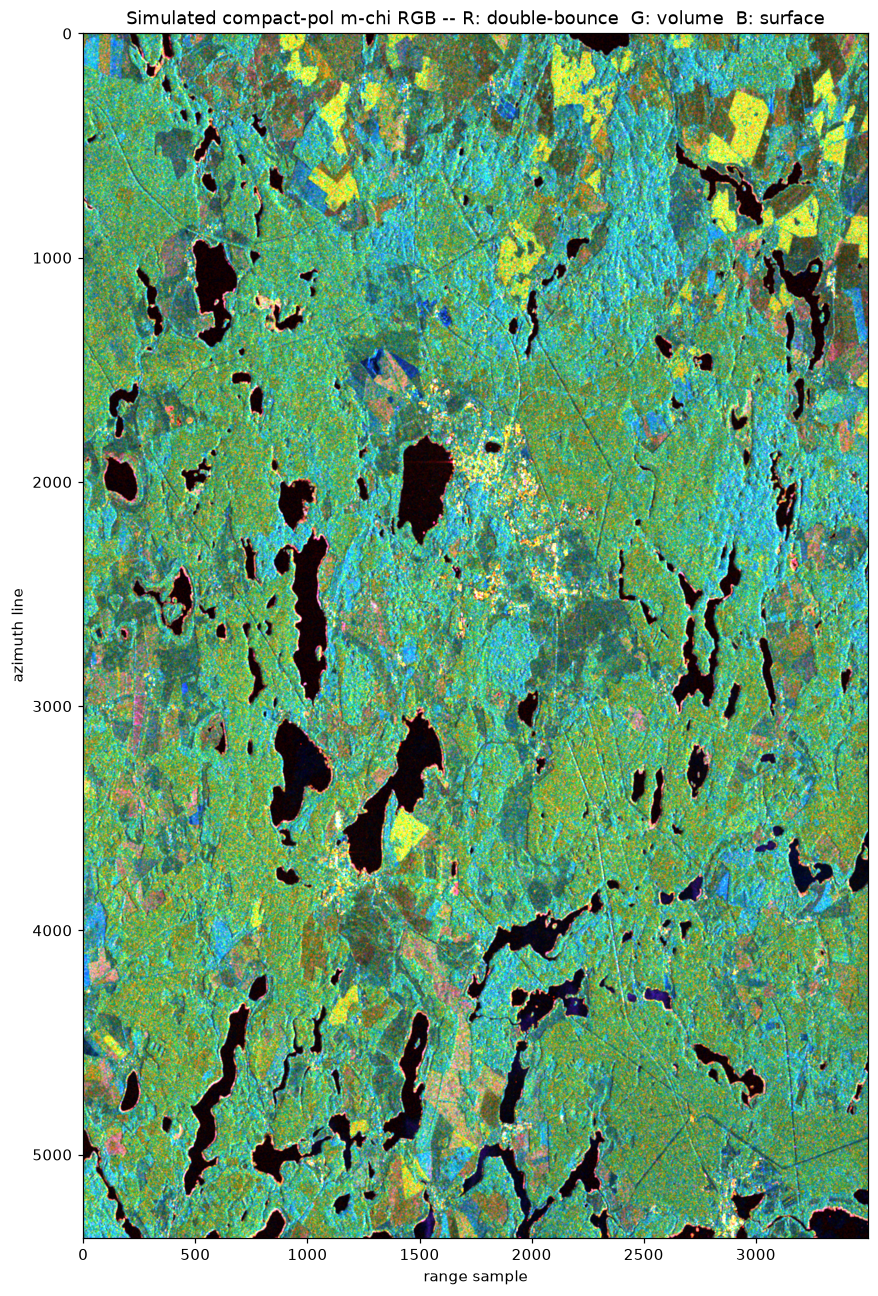

In [6]:
# Build and display the standard m-chi false-colour RGB composite from the simulated
# compact-pol decomposition: red = double-bounce, green = volume, blue = surface.

# 1. Contrast-stretch a single band to [0, 1] using its 2nd/98th percentiles as black/white
#    points, clipping outliers and replacing any NaN with 0 -- a simple visualization helper
#    so each channel uses its own full dynamic range in the composite.
def stretch(x, lo=2, hi=98):
    a, b = np.nanpercentile(x, [lo, hi])  # 2nd and 98th percentile
    return np.nan_to_num(np.clip((x - a) / (b - a), 0, 1))  # stretch to [0, 1], NaN -> 0


# 2. Assemble the RGB composite using amplitude (square root of power), not power itself,
#    matching the Pauli RGB convention used for the real quad-pol scene elsewhere in this
#    series: R = double-bounce, G = volume, B = surface.
mchi_rgb = np.dstack([stretch(np.sqrt(mc["pd"])), stretch(np.sqrt(mc["pv"])), stretch(np.sqrt(mc["ps"]))])

# 3. Display the composite in the SLC's native radar geometry (range sample x azimuth line),
#    with no terrain correction or geocoding applied.
plt.figure(figsize=(8, 12))
plt.imshow(mchi_rgb)  # the m-chi RGB composite
plt.title("Simulated compact-pol m-chi RGB -- R: double-bounce  G: volume  B: surface")  # title
plt.xlabel("range sample"); plt.ylabel("azimuth line")  # axis labels
plt.tight_layout()  # arrange

Visually this closely mirrors the real quad-pol Pauli RGB from `07_03_02_03_RADARSAT_PolSAR.ipynb`:
the same lakes read dark, the same forested moraine hills read green, and the same village
cluster stands out with a strong red (double-bounce) tint -- using only two simulated receive
channels instead of four real ones, exactly the compression compact-pol trades for quad-pol's
extra swath-width and data-rate cost.

## Takeaways and limitations

- `geolattice.rsense.sar.radarsat` ships the **native** RCM compact-pol pipeline unchanged from
  earlier in this session: `split_rrrl`, `rr_rl_to_stokes`, `rrrl_to_rhrv` and
  `compact_pol_mchi` read RCM's real circular-receive (RR/RL/RRRL\*) ARD product directly, no
  simulation involved. `data/` does not currently hold a real RCM compact-pol product (only an
  RCM dual-pol GRD and RCM InSAR pair), so that path is not demonstrated with real data here --
  the formulas and conventions follow NRCan/EODMS's own reference notebooks exactly
  (`rrrl_to_rhrv.ipynb`, `mchi_decomposition.ipynb`), as documented in each function's docstring.
- `simulate_compact_pol` (new) is specifically for missions **without** compact-pol hardware --
  RADARSAT-2 here -- and is a simulation of the *receive mode*, not of the data: every channel
  going in is real, measured backscatter from the real scene.
- The sign convention in `simulate_compact_pol` + `compact_pol_mchi`'s composition was verified
  two independent ways above: analytically exact on canonical pure-surface/pure-double-bounce
  scatterers, and empirically consistent with the real quad-pol H-alpha classification of the
  same scene (median fractions line up zone-by-zone, both correlations have the physically
  expected sign).
- **Pseudo-quad reconstruction** (Souyris/Nord methods, mentioned in the theory above) is
  deliberately not implemented: reconstructing a full 3x3 covariance matrix from only 2x2
  compact-pol data requires an extra modelling assumption (a fixed or iteratively-estimated
  cross-pol/co-pol energy ratio) with multiple incompatible published variants -- the same
  normalization/branching risk judged not worth taking for Freeman-Durden in the PolSAR
  notebook.
- No radiometric calibration applied -- harmless here since `m`, the ellipticity, and the m-chi
  power fractions are all scale-invariant ratios, but the absolute dB values printed above are
  relative, uncalibrated numbers.
- No terrain correction or geocoding -- results are in the SLC's own radar geometry, as for
  every other raw (non-ARD) RADARSAT product in this series.

#### References

- Raney, R. K. (2007). *Hybrid-polarity SAR architecture.* IEEE TGRS, 45(11), 3397-3404.
- Charbonneau, F. J., et al. (2010). *Compact polarimetry overview and applications assessment.*
  Canadian Journal of Remote Sensing, 36(sup2), S298-S315.
- Guo, X., Li, K., Shao, Y., et al. (2018). *Inversion of rice biophysical parameters using
  simulated compact polarimetric SAR C-band data.* Sensors, 18(7), 2271.
- Cloude, S. R., & Pottier, E. (1997). *An entropy based classification scheme for land
  applications of polarimetric SAR.* IEEE TGRS, 35(1), 68-78.
- NRCan/EODMS. `radarsat-notebooks` (`rrrl_to_rhrv.ipynb`, `mchi_decomposition.ipynb`).
  https://github.com/eodms-sgdot/radarsat-notebooks
